# 01 - Client Market Report

Notebook nay doc cac output da duoc pipeline sinh san. No khong chay lai pipeline va khong ghi de len output production.

Recommended flow truoc khi mo notebook:

```bash
python scripts/run_daily_pipeline.py --online --update-index --build-portfolio
```

Neu SSI rate limit:

```bash
python scripts/run_daily_pipeline.py --offline --build-portfolio
```

In [3]:
from pathlib import Path
import json
from datetime import datetime

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display


def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data").exists() and (candidate / "src").exists() and (candidate / "scripts").exists():
            return candidate
    return Path.cwd()


ROOT = find_project_root()
OUTPUT_DIR = ROOT / "data" / "output"
PROCESSED_DIR = ROOT / "data" / "processed"
missing_files = []


def load_parquet_safe(relative_path: str) -> pd.DataFrame:
    path = ROOT / relative_path
    if not path.exists():
        missing_files.append(relative_path)
        return pd.DataFrame()
    try:
        return pd.read_parquet(path)
    except Exception as exc:
        missing_files.append(f"{relative_path} (read_error: {exc})")
        return pd.DataFrame()


def load_json_safe(relative_path: str) -> dict:
    path = ROOT / relative_path
    if not path.exists():
        missing_files.append(relative_path)
        return {}
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except Exception as exc:
        missing_files.append(f"{relative_path} (read_error: {exc})")
        return {}


def latest_date(df: pd.DataFrame, columns=("date", "analysis_as_of", "source_latest_date")):
    if df.empty:
        return None
    for column in columns:
        if column not in df.columns:
            continue
        values = pd.to_datetime(df[column], errors="coerce").dropna()
        if not values.empty:
            return values.max().date().isoformat()
    return None


def choose_weight_column(df: pd.DataFrame) -> str | None:
    for column in ["risk_parity", "hrp", "inverse_volatility", "equal_weight"]:
        if column in df.columns:
            return column
    return None


def pct_text(value):
    if value is None or pd.isna(value):
        return "N/A"
    return f"{value * 100:.2f}%"


client_ready = load_parquet_safe("data/output/client_ready_watchlist.parquet")
trading_watchlist = load_parquet_safe("data/output/trading_watchlist.parquet")
research_candidates = load_parquet_safe("data/output/research_candidates.parquet")
portfolio_weights = load_parquet_safe("data/output/portfolio_weights.parquet")
capital_plan = load_parquet_safe("data/output/capital_plan.parquet")
stock_features = load_parquet_safe("data/processed/stock_features.parquet")
benchmark_vnindex = load_parquet_safe("data/processed/benchmark_vnindex.parquet")
sector_board = load_parquet_safe("data/output/sector_board.parquet")
sector_leaders = load_parquet_safe("data/output/sector_leaders.parquet")
pipeline_metadata = load_json_safe("data/output/pipeline_metadata.json")
portfolio_stack_metadata = load_json_safe("data/output/portfolio_stack_metadata.json")
sector_board_metadata = load_json_safe("data/output/sector_board_metadata.json")

cashflow_board = load_parquet_safe("data/output/cashflow_board.parquet")
sector_cashflow = load_parquet_safe("data/output/sector_cashflow.parquet")
watchlist_cashflow_confirmation = load_parquet_safe("data/output/watchlist_cashflow_confirmation.parquet")
cashflow_board_metadata = load_json_safe("data/output/cashflow_board_metadata.json")
portfolio_risk_report = load_json_safe("data/output/portfolio_risk_report.json")

report_generated_at = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
display(Markdown(f"Project root detected: `{ROOT}`"))
if missing_files:
    display(Markdown("**Missing / unreadable inputs:** " + ", ".join(f"`{item}`" for item in missing_files)))
else:
    display(Markdown("**All primary report inputs were loaded successfully.**"))

Project root detected: `/Users/jamesb/Desktop/vietnam-quant-research`

**All primary report inputs were loaded successfully.**

## 1. Title & Run Information

In [5]:
run_info = pd.DataFrame(
    [
        ("Report generated at", report_generated_at),
        ("Pipeline run timestamp", pipeline_metadata.get("run_timestamp", "N/A")),
        ("Pipeline mode", pipeline_metadata.get("run_mode", "N/A")),
        ("Freshness status", pipeline_metadata.get("freshness_status", "N/A")),
        ("Latest stock date", pipeline_metadata.get("latest_stock_date", latest_date(stock_features) or "N/A")),
        ("Latest benchmark date", pipeline_metadata.get("latest_benchmark_date", latest_date(benchmark_vnindex) or "N/A")),
        ("Portfolio stack status", pipeline_metadata.get("portfolio_stack", {}).get("status", "DISABLED")),
        ("Online update status", pipeline_metadata.get("online_update", {}).get("status", "SKIPPED")),
    ],
    columns=["Metric", "Value"],
)
run_info

,Metric,Value
0,Report generated at,2026-07-01 23:30:32
1,Pipeline run timestamp,2026-07-01T16:06:31+00:00
2,Pipeline mode,offline
3,Freshness status,OK
4,Latest stock date,2026-06-30
5,Latest benchmark date,2026-06-30
6,Portfolio stack status,OK
7,Online update status,SKIPPED


## 2. Executive Summary

In [7]:
watchlist_counts = pipeline_metadata.get("watchlist_counts", {})
research_count = watchlist_counts.get("research_candidates", {}).get("rows", len(research_candidates))
trading_count = watchlist_counts.get("trading_watchlist", {}).get("rows", len(trading_watchlist))
client_ready_count = watchlist_counts.get("client_ready_watchlist", {}).get("rows", len(client_ready))
portfolio_enabled = pipeline_metadata.get("portfolio_stack", {}).get("enabled", False)
portfolio_status = pipeline_metadata.get("portfolio_stack", {}).get("status", "DISABLED")
warnings = list(pipeline_metadata.get("warnings", []))
online_update = pipeline_metadata.get("online_update", {})

summary_lines = [
    f"- Freshness status: **{pipeline_metadata.get('freshness_status', 'N/A')}**.",
    f"- Research universe currently contains **{research_count}** candidates.",
    f"- Trading watchlist currently contains **{trading_count}** names.",
    f"- Client-ready watchlist currently contains **{client_ready_count}** names.",
    f"- Portfolio stack status: **{portfolio_status}** (enabled={portfolio_enabled}).",
]
if online_update.get("status") not in {None, "OK", "SKIPPED"}:
    summary_lines.append(
        f"- Online update warning: **{online_update.get('error_category', 'UNKNOWN_ERROR')}** - {online_update.get('error_message', 'No detail')}"
    )
if warnings:
    summary_lines.append("- Key warnings: " + "; ".join(str(item) for item in warnings[:5]))
if missing_files:
    summary_lines.append("- Missing inputs detected: " + ", ".join(str(item) for item in missing_files))

display(Markdown("\n".join(summary_lines)))

- Freshness status: **OK**.
- Research universe currently contains **108** candidates.
- Trading watchlist currently contains **10** names.
- Client-ready watchlist currently contains **10** names.
- Portfolio stack status: **OK** (enabled=True).

## 3. Market Context

,Metric,Value
0,Latest close,1871.003722
1,5D return,-0.48%
2,10D return,2.88%
3,20D return,1.84%
4,Latest drawdown vs rolling peak,-3.52%


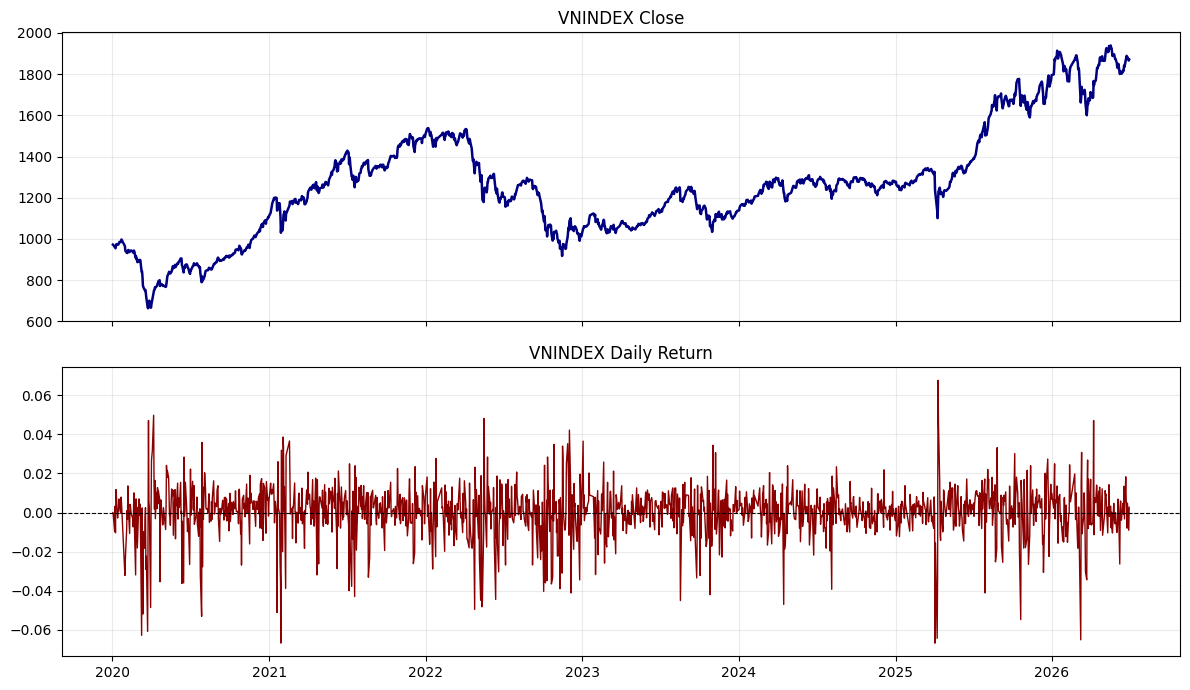

In [9]:
if benchmark_vnindex.empty:
    display(Markdown("Benchmark VNINDEX data is missing, so market context is limited."))
else:
    bench = benchmark_vnindex.copy()
    bench["date"] = pd.to_datetime(bench["date"], errors="coerce")
    bench = bench.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)
    if "return_1d" not in bench.columns and "close" in bench.columns:
        bench["return_1d"] = bench["close"].pct_change(1)
    for period in [5, 10, 20]:
        col = f"return_{period}d"
        if col not in bench.columns and "close" in bench.columns:
            bench[col] = bench["close"].pct_change(period)
    latest = bench.iloc[-1]
    rolling_peak = bench["close"].cummax() if "close" in bench.columns else pd.Series(dtype=float)
    latest_drawdown = None
    if not rolling_peak.empty:
        latest_drawdown = float((bench["close"] / rolling_peak - 1.0).iloc[-1])
    context_rows = [
        ("Latest close", latest.get("close", "N/A")),
        ("5D return", pct_text(latest.get("return_5d"))),
        ("10D return", pct_text(latest.get("return_10d"))),
        ("20D return", pct_text(latest.get("return_20d"))),
        ("Latest drawdown vs rolling peak", pct_text(latest_drawdown)),
    ]
    display(pd.DataFrame(context_rows, columns=["Metric", "Value"]))
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    axes[0].plot(bench["date"], bench["close"], color="navy", linewidth=1.8)
    axes[0].set_title("VNINDEX Close")
    axes[0].grid(alpha=0.25)
    axes[1].plot(bench["date"], bench.get("return_1d", pd.Series(index=bench.index, dtype=float)).fillna(0.0), color="darkred", linewidth=1.0)
    axes[1].axhline(0.0, color="black", linewidth=0.8, linestyle="--")
    axes[1].set_title("VNINDEX Daily Return")
    axes[1].grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## 4. Market Breadth / Regime

In [11]:
if stock_features.empty:
    display(Markdown("Stock feature data is missing, so breadth and regime review cannot be computed."))
else:
    stock = stock_features.copy()
    stock["date"] = pd.to_datetime(stock["date"], errors="coerce")
    stock = stock.dropna(subset=["date"]).sort_values(["date", "symbol"])
    latest_stock_date = stock["date"].max()
    latest_slice = stock[stock["date"] == latest_stock_date].copy()
    breadth_rows = []
    if "return_1d" in latest_slice.columns:
        breadth_rows.extend([
            ("Advancers", int((latest_slice["return_1d"] > 0).sum())),
            ("Decliners", int((latest_slice["return_1d"] < 0).sum())),
            ("Unchanged / NA", int((latest_slice["return_1d"].fillna(0) == 0).sum())),
        ])
    else:
        breadth_rows.append(("Advancers / Decliners", "Column return_1d is not available"))
    if "above_ma20" in latest_slice.columns:
        breadth_rows.append(("Pct above MA20", pct_text(latest_slice["above_ma20"].mean())))
    else:
        breadth_rows.append(("Pct above MA20", "Column above_ma20 is not available"))
    if "above_ma50" in latest_slice.columns:
        breadth_rows.append(("Pct above MA50", pct_text(latest_slice["above_ma50"].mean())))
    else:
        breadth_rows.append(("Pct above MA50", "Column above_ma50 is not available"))
    regime_note = "No regime column found in stock_features."
    for regime_col in ["market_regime", "volatility_regime", "regime"]:
        if regime_col in latest_slice.columns:
            counts = latest_slice[regime_col].fillna("Unknown").value_counts().to_dict()
            regime_note = ", ".join(f"{k}: {v}" for k, v in counts.items())
            break
    display(pd.DataFrame(breadth_rows, columns=["Metric", "Value"]))
    display(Markdown(f"**Regime note:** {regime_note}"))

,Metric,Value
0,Advancers,98
1,Decliners,77
2,Unchanged / NA,32
3,Pct above MA20,51.21%
4,Pct above MA50,40.58%


**Regime note:** Low Vol: 114, Normal Vol: 50, High Vol: 25, Stress Vol: 10, Panic Vol: 5, Unknown: 3

## 5. Watchlist Overview and 6. Client-Ready Watchlist

In [13]:
overview = pd.DataFrame(
    [
        ("Research candidates", len(research_candidates), latest_date(research_candidates) or "N/A"),
        ("Trading watchlist", len(trading_watchlist), latest_date(trading_watchlist) or "N/A"),
        ("Client-ready watchlist", len(client_ready), latest_date(client_ready) or "N/A"),
    ],
    columns=["Bucket", "Count", "Latest Date"],
)
overview

if client_ready.empty:
    display(Markdown("Client-ready watchlist is empty. Review pipeline warnings and candidate filters before sending to the client."))
else:
    important_cols = [
        "rank", "symbol", "date", "close", "final_score", "candidate_tier", "confidence_label",
        "volatility_regime", "risk_reward_estimate", "reason", "exclusion_reason"
    ]
    show_cols = [col for col in important_cols if col in client_ready.columns]
    display(client_ready[show_cols].head(10))
    bullet_lines = []
    for _, row in client_ready.head(10).iterrows():
        reason = row.get("reason", "No qualitative reason field available")
        tier = row.get("candidate_tier", "N/A")
        confidence = row.get("confidence_label", "N/A")
        regime = row.get("volatility_regime", "N/A")
        exclusion = row.get("exclusion_reason", "")
        warning_note = f" Caution: {exclusion}." if isinstance(exclusion, str) and exclusion.strip() else ""
        bullet_lines.append(
            f"- **{row.get('symbol', 'N/A')}** | tier: **{tier}** | confidence: **{confidence}** | regime: **{regime}**. Main strength: {reason}.{warning_note}"
        )
    display(Markdown("\n".join(bullet_lines)))

,rank,symbol,date,close,final_score,candidate_tier,confidence_label,volatility_regime,risk_reward_estimate,reason,exclusion_reason
0,1,CTS,2026-06-30,26800,87.76,Client Ready,High,High Vol,5.14,"Xu hướng tăng duy trì, rs vượt vnindex, động l...",
1,2,MSB,2026-06-30,15950,87.24,Client Ready,High,Normal Vol,18.57,"Xu hướng tăng duy trì, rs vượt vnindex, động l...",
2,3,STB,2026-06-30,75300,86.23,Client Ready,High,Normal Vol,10.11,"Xu hướng tăng duy trì, rs vượt vnindex, động l...",
3,4,POW,2026-06-30,14750,85.08,Client Ready,High,Normal Vol,5.55,"Xu hướng tăng duy trì, rs vượt vnindex, động l...",
4,5,ABB,2026-06-30,18100,84.13,Client Ready,High,Normal Vol,11.65,"Xu hướng tăng duy trì, rs vượt vnindex, động l...",
5,6,BMP,2026-06-30,154000,83.31,Client Ready,High,Normal Vol,10.29,"Xu hướng tăng duy trì, rs vượt vnindex, động l...",
6,7,SSB,2026-06-30,15900,82.80,Client Ready,High,High Vol,6.34,"Xu hướng tăng duy trì, rs vượt vnindex, động l...",
7,8,VAB,2026-06-30,11250,82.67,Client Ready,High,Normal Vol,5.79,"Xu hướng tăng duy trì, rs vượt vnindex, động l...",
8,9,BVB,2026-06-30,13700,82.45,Client Ready,High,Low Vol,3.70,"Xu hướng tăng duy trì, rs vượt vnindex, động l...",
9,10,SAB,2026-06-30,48700,82.30,Client Ready,High,Low Vol,5.42,"Xu hướng tăng duy trì, rs vượt vnindex, động l...",


- **CTS** | tier: **Client Ready** | confidence: **High** | regime: **High Vol**. Main strength: Xu hướng tăng duy trì, rs vượt vnindex, động lượng tốt..
- **MSB** | tier: **Client Ready** | confidence: **High** | regime: **Normal Vol**. Main strength: Xu hướng tăng duy trì, rs vượt vnindex, động lượng tốt..
- **STB** | tier: **Client Ready** | confidence: **High** | regime: **Normal Vol**. Main strength: Xu hướng tăng duy trì, rs vượt vnindex, động lượng tốt..
- **POW** | tier: **Client Ready** | confidence: **High** | regime: **Normal Vol**. Main strength: Xu hướng tăng duy trì, rs vượt vnindex, động lượng tốt..
- **ABB** | tier: **Client Ready** | confidence: **High** | regime: **Normal Vol**. Main strength: Xu hướng tăng duy trì, rs vượt vnindex, động lượng tốt..
- **BMP** | tier: **Client Ready** | confidence: **High** | regime: **Normal Vol**. Main strength: Xu hướng tăng duy trì, rs vượt vnindex, động lượng tốt..
- **SSB** | tier: **Client Ready** | confidence: **High** | regime: **High Vol**. Main strength: Xu hướng tăng duy trì, rs vượt vnindex, động lượng tốt..
- **VAB** | tier: **Client Ready** | confidence: **High** | regime: **Normal Vol**. Main strength: Xu hướng tăng duy trì, rs vượt vnindex, động lượng tốt..
- **BVB** | tier: **Client Ready** | confidence: **High** | regime: **Low Vol**. Main strength: Xu hướng tăng duy trì, rs vượt vnindex, động lượng tốt..
- **SAB** | tier: **Client Ready** | confidence: **High** | regime: **Low Vol**. Main strength: Xu hướng tăng duy trì, rs vượt vnindex, động lượng tốt..

## 7. Portfolio Construction and 8. Risk Management

Using **risk_parity** as the primary displayed allocation column. These weights should be interpreted as a risk-framework allocation, not an all-in instruction.

,symbol,risk_parity,source_latest_date
0,SSB,0.161972,2026-06-30
1,BMP,0.127104,2026-06-30
2,POW,0.121587,2026-06-30
3,VAB,0.113975,2026-06-30
4,ABB,0.106189,2026-06-30
5,STB,0.093377,2026-06-30
6,BVB,0.083475,2026-06-30
7,CTS,0.078615,2026-06-30
8,SAB,0.056965,2026-06-30
9,MSB,0.056741,2026-06-30


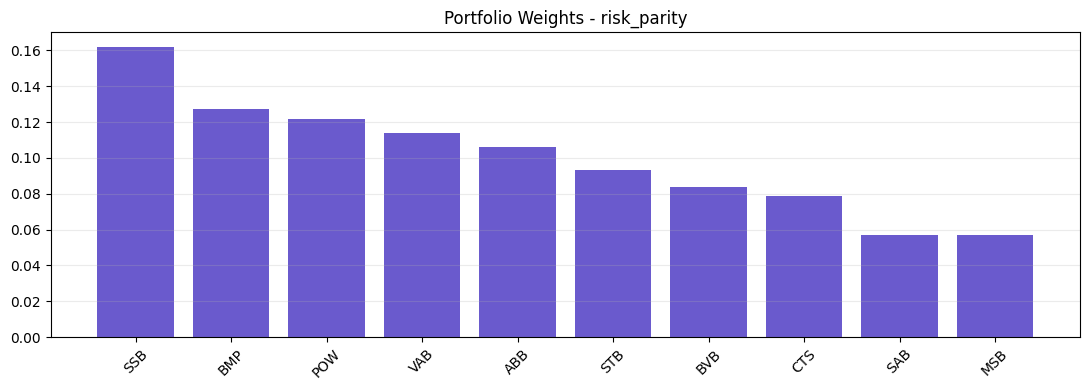

Sector grouping is not available in `portfolio_weights.parquet`.

,Risk Metric,Value
0,annual_return,0.161935
1,annual_volatility,0.113466
2,max_drawdown,-0.16389
3,sharpe_ratio,1.380053
4,sortino_ratio,2.010197
5,beta,0.345815
6,var_95,-0.009905
7,cvar_95,-0.016853
8,effective_n,9.109772
9,allocator_used,risk_parity


,symbol,trade_edge_score,conviction_score_resolved,volatility_regime,risk_pct_effective,quantity,position_value,position_pct_nav,stop_price
0,ABB,None,50.0,Normal Vol,0.0085,5573,100871300.0,0.100871,17328.571429
1,BMP,None,50.0,Normal Vol,0.0085,629,96866000.0,0.096866,146300.000000
2,MSB,None,50.0,Normal Vol,0.0085,3379,53895050.0,0.053895,15264.285714
3,SAB,None,50.0,Low Vol,0.0100,1111,54105700.0,0.054106,46871.428571
4,SSB,None,50.0,High Vol,0.0070,4,63600.0,0.000064,15228.571429
5,VAB,None,50.0,Normal Vol,0.0085,9624,108270000.0,0.108270,10785.714286


Capital allocation should be interpreted as staged, risk-budgeted sizing rather than an all-in deployment plan.

In [15]:
weight_col = choose_weight_column(portfolio_weights)
if portfolio_weights.empty or weight_col is None:
    display(Markdown("Portfolio weight file is missing or does not contain a recognized allocation column."))
else:
    portfolio_view = portfolio_weights[[col for col in ["symbol", weight_col, "source_latest_date"] if col in portfolio_weights.columns]].copy()
    portfolio_view = portfolio_view.sort_values(weight_col, ascending=False).reset_index(drop=True)
    display(Markdown(f"Using **{weight_col}** as the primary displayed allocation column. These weights should be interpreted as a risk-framework allocation, not an all-in instruction."))
    display(portfolio_view)
    plt.figure(figsize=(11, 4))
    plt.bar(portfolio_view["symbol"], portfolio_view[weight_col], color="slateblue")
    plt.title(f"Portfolio Weights - {weight_col}")
    plt.xticks(rotation=45)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
    if "sector" in portfolio_weights.columns:
        sector_view = portfolio_weights.groupby("sector", dropna=False)[weight_col].sum().reset_index().sort_values(weight_col, ascending=False)
        display(sector_view)
    else:
        display(Markdown("Sector grouping is not available in `portfolio_weights.parquet`."))

risk_keys = [
    "annual_return", "annual_volatility", "max_drawdown", "sharpe_ratio",
    "sortino_ratio", "beta", "var_95", "cvar_95", "effective_n", "allocator_used"
]
risk_rows = [(key, portfolio_risk_report.get(key, "N/A")) for key in risk_keys]
display(pd.DataFrame(risk_rows, columns=["Risk Metric", "Value"]))

if capital_plan.empty:
    display(Markdown("Capital plan is not available, so capital allocation review is limited."))
else:
    capital_cols = [
        "symbol", "trade_edge_score", "conviction_score_resolved", "volatility_regime",
        "risk_pct_effective", "quantity", "position_value", "position_pct_nav", "stop_price"
    ]
    capital_show = [col for col in capital_cols if col in capital_plan.columns]
    display(capital_plan[capital_show].sort_values(capital_show[0]).reset_index(drop=True))
    display(Markdown("Capital allocation should be interpreted as staged, risk-budgeted sizing rather than an all-in deployment plan."))

## 9. Scenario Analysis and 10. Client Action Plan

In [17]:
bullish_text = (
    "- **Bullish scenario:** if VNINDEX confirms trend continuation, priority should shift toward the highest-conviction client-ready names,"
    " with scaling based on portfolio weights and capital-plan risk limits rather than aggressive full deployment."
)
base_text = (
    "- **Base scenario:** if the market stays range-bound or continues to accumulate, keep the research and trading watchlists active,"
    " but deploy only partial size into names with stable confidence labels and acceptable volatility regime."
)
bearish_text = (
    "- **Bearish scenario:** if support breaks or volatility expands, reduce gross exposure, tighten stop discipline,"
    " and move weaker watchlist names back into observation mode instead of forcing entries."
)

client_action_lines = [
    "- **Follow closely:** names already in the client-ready bucket with strong confidence and no major exclusion reason.",
    "- **Scale in gradually:** names supported by the portfolio weight framework and capital plan, especially where risk budgets remain modest.",
    "- **Wait for confirmation:** names still attractive on research merit but lacking a cleaner tactical setup or carrying a warning note.",
    "- **Reduce exposure when needed:** if benchmark momentum weakens materially, breadth narrows, or volatility regime deteriorates."
]

display(Markdown("\n".join([bullish_text, base_text, bearish_text, "", *client_action_lines])))

- **Bullish scenario:** if VNINDEX confirms trend continuation, priority should shift toward the highest-conviction client-ready names, with scaling based on portfolio weights and capital-plan risk limits rather than aggressive full deployment.
- **Base scenario:** if the market stays range-bound or continues to accumulate, keep the research and trading watchlists active, but deploy only partial size into names with stable confidence labels and acceptable volatility regime.
- **Bearish scenario:** if support breaks or volatility expands, reduce gross exposure, tighten stop discipline, and move weaker watchlist names back into observation mode instead of forcing entries.

- **Follow closely:** names already in the client-ready bucket with strong confidence and no major exclusion reason.
- **Scale in gradually:** names supported by the portfolio weight framework and capital plan, especially where risk budgets remain modest.
- **Wait for confirmation:** names still attractive on research merit but lacking a cleaner tactical setup or carrying a warning note.
- **Reduce exposure when needed:** if benchmark momentum weakens materially, breadth narrows, or volatility regime deteriorates.

## Sector Board / Sector Rotation

In [19]:
if sector_board.empty:
    display(Markdown("Sector Board output is missing. Run `python scripts/build_sector_board.py` or add `--build-sector` to the daily pipeline when you want sector-level rotation context."))
else:
    coverage = sector_board_metadata.get("""mapping_coverage""") if sector_board_metadata else None
    sector_cols = [
        "sector", "sector_rank", "sector_label", "sector_total_score", "sector_strength_score",
        "sector_flow_score", "sector_breadth_score", "relative_return_20d_vs_vnindex",
        "pct_positive_20d", "pct_above_ma20", "n_client_ready_symbols", "n_trading_watchlist_symbols",
        "top_symbol_1", "top_symbol_2", "top_symbol_3"
    ]
    show_cols = [col for col in sector_cols if col in sector_board.columns]
    if coverage is not None and coverage < 0.80:
        display(Markdown("**Warning:** Sector Board chua du coverage de ket luan sector rotation toan thi truong."))
    display(sector_board[show_cols].head(10))
    if sector_board_metadata:
        warnings = sector_board_metadata.get("warnings", [])
        summary = [
            f"- Sector Board status: **{sector_board_metadata.get('status', 'N/A')}**",
            f"- Latest sector date: **{sector_board_metadata.get('latest_date', 'N/A')}**",
            f"- Number of sectors: **{sector_board_metadata.get('n_sectors', 'N/A')}**",
            f"- Mapping coverage: **{pct_text(sector_board_metadata.get('mapping_coverage'))}**",
            f"- Unknown sector ratio: **{pct_text(sector_board_metadata.get('unknown_ratio'))}**",
        ]
        if warnings:
            summary.append("- Sector warnings: " + "; ".join(str(item) for item in warnings[:5]))
        display(Markdown("\n".join(summary)))
    if not sector_leaders.empty:
        leader_cols = [
            "sector", "symbol", "leader_rank_in_sector", "return_20d", "return_5d",
            "volume_ratio_20d", "is_client_ready", "is_trading_watchlist", "leader_reason"
        ]
        display(sector_leaders[[col for col in leader_cols if col in sector_leaders.columns]].head(15))
    display(Markdown("Sector Board should be used as a top-down context layer: prioritize sectors with stronger breadth, relative performance, and confirmed watchlist participation before drilling into single-stock trade ideas."))


,sector,sector_rank,sector_label,sector_total_score,sector_strength_score,sector_flow_score,sector_breadth_score,relative_return_20d_vs_vnindex,pct_positive_20d,pct_above_ma20,n_client_ready_symbols,n_trading_watchlist_symbols,top_symbol_1,top_symbol_2,top_symbol_3
0,Banking,1,LEADING,79.473958,100.000000,40.187500,84.375000,0.052472,0.916667,0.916667,6,6,MSB,TPB,SSB
1,Securities,2,LEADING,75.208333,95.833333,68.833333,67.000000,0.037342,0.800000,0.640000,1,1,CTS,BSI,FTS
2,Food & Beverage,3,IMPROVING,72.547676,91.666667,56.729167,63.461538,0.028586,0.769231,0.692308,1,1,SAB,BHN,VNM
3,Consumer Discretionary,4,IMPROVING,63.778646,76.041667,70.114583,41.666667,-0.014338,0.583333,0.500000,0,0,SAV,KBC,CCI
4,Transportation & Logistics,5,IMPROVING,61.257258,73.958333,68.468750,39.893617,-0.012292,0.425532,0.425532,0,0,VCG,HVN,VJC
5,Business Services,6,NEUTRAL,59.645833,86.458333,26.916667,60.000000,0.017289,0.600000,0.800000,0,0,TVC,PAN,APC
6,Consumer Staples,7,NEUTRAL,58.770833,60.937500,55.916667,50.000000,-0.024911,0.461538,0.538462,0,0,ANV,VHC,MSN
7,UNKNOWN,8,NEUTRAL,58.184896,79.687500,66.072917,29.166667,-0.009627,0.388889,0.277778,0,0,VVS,AMP,AG1
8,Construction & Infrastructure,9,NEUTRAL,53.601700,57.291667,64.187500,33.552632,-0.023047,0.315789,0.394737,0,0,PC1,CII,TTA
9,Chemicals,10,NEUTRAL,49.026910,52.083333,37.218750,38.888889,-0.021612,0.444444,0.444444,0,0,VAF,ADP,DPM


- Sector Board status: **OK**
- Latest sector date: **2026-06-30**
- Number of sectors: **24**
- Mapping coverage: **96.41%**
- Unknown sector ratio: **3.59%**

,sector,symbol,leader_rank_in_sector,return_20d,return_5d,volume_ratio_20d,is_client_ready,is_trading_watchlist,leader_reason
0,Agriculture & Aquaculture,ACL,1,-0.048507,0.028226,0.277228,False,False,"20D return -4.9%, volume ratio 0.28x"
1,Agriculture & Aquaculture,AAM,2,0.006098,-0.029412,1.535509,False,False,"20D return 0.6%, volume ratio 1.54x"
2,Agriculture & Aquaculture,DAT,3,0.012821,-0.001264,0.077220,False,False,"20D return 1.3%, volume ratio 0.08x"
3,Banking,MSB,1,0.115385,0.029032,0.169118,True,True,"20D return 11.5%, volume ratio 0.17x, client-r..."
4,Banking,TPB,2,0.051282,0.015480,0.534754,False,False,"20D return 5.1%, volume ratio 0.53x"
5,Banking,SSB,3,0.104167,0.049505,0.179713,True,True,"20D return 10.4%, volume ratio 0.18x, client-r..."
6,Banking,TCB,4,0.051724,0.046802,0.236886,False,False,"20D return 5.2%, volume ratio 0.24x"
7,Banking,OCB,5,0.095181,0.032573,0.405564,False,False,"20D return 9.5%, volume ratio 0.41x"
8,Business Services,TVC,1,0.183908,0.030000,0.000000,False,False,"20D return 18.4%, volume ratio 0.00x"
9,Business Services,PAN,2,-0.021231,0.015419,0.165787,False,False,"20D return -2.1%, volume ratio 0.17x"


Sector Board should be used as a top-down context layer: prioritize sectors with stronger breadth, relative performance, and confirmed watchlist participation before drilling into single-stock trade ideas.

## Cashflow Board / Money Flow Confirmation


In [21]:
if cashflow_board.empty or sector_cashflow.empty or watchlist_cashflow_confirmation.empty:
    display(Markdown("Cashflow Board output is missing. Run  or add  to the daily pipeline when you want money flow context."))
else:
    display(Markdown("### 1. Top Sectors by Cashflow Score"))
    sector_show_cols = [
        "sector", "sector_cashflow_score", "sector_cashflow_rank", "sector_cashflow_label",
        "n_symbols_with_valid_cashflow", "sector_score_quality", "sector_score_warning", "top_cashflow_symbols"
    ]
    show_sec = sector_cashflow[[col for col in sector_show_cols if col in sector_cashflow.columns]].head(5)
    display(show_sec)
    
    # Check for warnings in top sectors
    for _, row in sector_cashflow.head(5).iterrows():
        if row.get("sector_sample_size_label") == "SMALL":
            display(Markdown(f"**Warning:** Ngành  có số lượng mã rất nhỏ ({row['n_symbols_with_valid_cashflow']} mã), điểm số có thể bị lệch do outlier."))
            
    display(Markdown("### 2. Top Symbols by Cashflow Score"))
    symbol_show_cols = [
        "symbol", "sector", "close", "cashflow_value", "volume_ratio_20d",
        "cashflow_intensity_score", "cashflow_score", "cashflow_state", "cashflow_label"
    ]
    display(cashflow_board[[col for col in symbol_show_cols if col in cashflow_board.columns]].sort_values("cashflow_score", ascending=False).head(10))
    
    display(Markdown("### 3. Watchlist Confirmation Status"))
    confirm_show_cols = [
        "symbol", "sector", "watchlist_tier", "cashflow_score", "cashflow_state",
        "cashflow_label", "confirmation_status", "cashflow_reason", "cashflow_action_note"
    ]
    
    # Split watchlists
    client_ready_confirm = watchlist_cashflow_confirmation[
        (watchlist_cashflow_confirmation["watchlist_tier"] == "client_ready")
    ]
    
    if not client_ready_confirm.empty:
        display(Markdown("#### Client-Ready Watchlist - Dòng tiền xác nhận tích cực"))
        positive = client_ready_confirm[client_ready_confirm["confirmation_status"].isin(["STRONG_CONFIRMED", "CONFIRMED", "NEUTRAL_CONFIRMED"])]
        if not positive.empty:
            display(positive[[col for col in confirm_show_cols if col in positive.columns]])
        else:
            display(Markdown("*Không có mã nào.*"))
            
        display(Markdown("#### Client-Ready Watchlist - Cần theo dõi hoặc cẩn trọng (Watch / Caution / Check Required)"))
        cautions = client_ready_confirm[client_ready_confirm["confirmation_status"].isin(["WATCH", "CAUTION", "CHECK_REQUIRED", "REJECT"])]
        if not cautions.empty:
            display(cautions[[col for col in confirm_show_cols if col in cautions.columns]])
        else:
            display(Markdown("*Không có mã nào.*"))
            
    # Dynamic Commentary
    top_sector = sector_cashflow.iloc[0]["sector"] if not sector_cashflow.empty else "N/A"
    top_sector_score = sector_cashflow.iloc[0]["sector_cashflow_score"] if not sector_cashflow.empty else 0.0
    confirmed_count = len(client_ready_confirm[client_ready_confirm["confirmation_status"].isin(["STRONG_CONFIRMED", "CONFIRMED"])])
    caution_count = len(client_ready_confirm[client_ready_confirm["confirmation_status"].isin(["CAUTION", "CHECK_REQUIRED"])])
    
    display(Markdown("### 4. Money Flow Commentary"))
    display(Markdown(
        f"**Nhận định nhanh:** Nhóm ngành dẫn đầu dòng tiền hiện tại là **{top_sector}** với điểm số **{top_sector_score:.1f}**. "
        f"Trong watchlist client-ready, có **{confirmed_count}** mã được dòng tiền xác nhận tích cực, và **{caution_count}** mã cần lưu ý/kiểm tra lại dòng tiền hoặc thanh khoản."
    ))


### 1. Top Sectors by Cashflow Score

,sector,sector_cashflow_score,sector_cashflow_rank,sector_cashflow_label,n_symbols_with_valid_cashflow,sector_score_quality,sector_score_warning,top_cashflow_symbols
0,Securities,34.981186,1,WEAK,15,MEDIUM,,"BSI, CTS, FTS"
1,Banking,34.339688,2,WEAK,20,HIGH,,"TPB, OCB, NAB"
2,Consumer Discretionary,30.657916,3,WEAK,9,MEDIUM,,"SAV, CCI, TMT"
3,Insurance,29.888694,4,WEAK,3,LOW,Small sample size (N < 5) may skew score,"AIC, PGI, BMI"
4,Transportation & Logistics,28.758216,5,WEAK,28,HIGH,,"VCG, LAF, NCT"


**Warning:** Ngành  có số lượng mã rất nhỏ (3 mã), điểm số có thể bị lệch do outlier.

### 2. Top Symbols by Cashflow Score

,symbol,sector,close,cashflow_value,volume_ratio_20d,cashflow_intensity_score,cashflow_score,cashflow_state,cashflow_label
83,BSI,Securities,36450,3.510431e+10,1.918074,96.456693,91.654873,CONFIRMED_INFLOW,STRONG
120,CTS,Securities,26800,7.006488e+10,1.529163,94.356955,88.733776,CONFIRMED_INFLOW,STRONG
451,VCG,Transportation & Logistics,21000,3.764208e+10,0.635261,86.089239,86.359367,NEUTRAL,IMPROVING
176,FTS,Securities,27300,2.748432e+10,0.710964,87.795276,86.019296,NEUTRAL,IMPROVING
428,TPB,Banking,16400,1.120800e+11,0.534754,83.464567,84.951321,DRY_UP_WATCH,IMPROVING
432,TRC,Materials,80200,1.796301e+10,8.995984,99.737533,84.936702,CONFIRMED_INFLOW,STRONG
304,ORS,Securities,13650,2.050254e+10,0.491294,81.758530,83.848883,NEUTRAL,IMPROVING
335,PVD,Energy,32450,2.180028e+10,0.282611,70.734908,83.237925,NEUTRAL,IMPROVING
41,AMP,UNKNOWN,15500,8.525000e+07,1.153040,93.044619,82.842227,NEUTRAL,IMPROVING
181,GEX,Technology & Communications,31450,1.749361e+11,0.585250,84.776903,82.240731,DRY_UP_WATCH,IMPROVING


### 3. Watchlist Confirmation Status

... (2 outputs left out)

#### Client-Ready Watchlist - Cần theo dõi hoặc cẩn trọng (Watch / Caution / Check Required)

,symbol,sector,watchlist_tier,cashflow_score,cashflow_state,cashflow_label,confirmation_status,cashflow_reason,cashflow_action_note
2,SAB,Food & Beverage,client_ready,77.326242,DRY_UP_WATCH,IMPROVING,WATCH,Theo dõi kiệt cung (Dry-up): giá giữ nền ổn đị...,"Theo dõi chặt chẽ, chuẩn bị mua thăm dò khi có..."
4,VAB,Banking,client_ready,74.658635,DRY_UP_WATCH,IMPROVING,WATCH,Theo dõi kiệt cung (Dry-up): giá giữ nền ổn đị...,"Theo dõi chặt chẽ, chuẩn bị mua thăm dò khi có..."
8,ABB,Banking,client_ready,59.703920,CHECK_REQUIRED,NEUTRAL,CHECK_REQUIRED,Cần kiểm tra: volume hiện tại bằng 0 hoặc thiế...,Tạm ngưng giao dịch để xác minh dữ liệu giá/kh...
9,BVB,Banking,client_ready,52.474218,CHECK_REQUIRED,NEUTRAL,CHECK_REQUIRED,Cần kiểm tra: volume hiện tại bằng 0 hoặc thiế...,Tạm ngưng giao dịch để xác minh dữ liệu giá/kh...


### 4. Money Flow Commentary

**Nhận định nhanh:** Nhóm ngành dẫn đầu dòng tiền hiện tại là **Securities** với điểm số **35.0**. Trong watchlist client-ready, có **6** mã được dòng tiền xác nhận tích cực, và **2** mã cần lưu ý/kiểm tra lại dòng tiền hoặc thanh khoản.

### 5. Mã cần kiểm tra dữ liệu trước khi hành động

Danh sách các cổ phiếu không đủ điều kiện giao dịch hoặc gặp lỗi dữ liệu (latest volume = 0, cashflow CHECK_REQUIRED, stale data).

In [ ]:
dr_path = ROOT / "data/output/data_review_watchlist.parquet"
if dr_path.exists():
    try:
        dr_df = pd.read_parquet(dr_path)
        if not dr_df.empty:
            display(Markdown("**CẢNH BÁO ĐẶC BIỆT:** Phát hiện cổ phiếu lỗi dữ liệu hoặc dòng tiền yếu cần kiểm tra!"))
            display(dr_df[["symbol", "latest_date", "latest_volume", "latest_close", "cashflow_data_status", "confirmation_status", "eligibility_reason", "recommended_action"]])
        else:
            display(Markdown("*Không có cổ phiếu nào bị cảnh báo chất lượng dữ liệu ở phase này.*"))
    except Exception as e:
        display(Markdown(f"**Lỗi đọc data_review_watchlist:** {e}"))
else:
    display(Markdown("*Không tìm thấy danh sách kiểm tra dữ liệu (data_review_watchlist).*"))


## Research Notes / Investment Thesis
Lớp phân tích định tính (Narrative Thesis) chuyển hóa các bằng chứng định lượng thành luận điểm đầu tư, thiết lập kỹ thuật, rủi ro chính và kịch bản hành động cụ thể cho từng mã cổ phiếu trong Watchlist.

In [23]:
import pandas as pd
import json
from pathlib import Path
from IPython.display import display, Markdown

index_path = ROOT / "data/output/research_notes_index.parquet"
meta_path = ROOT / "data/output/research_notes_metadata.json"

if not index_path.exists() or not meta_path.exists():
    display(Markdown("**Cảnh báo:** Chưa tạo lớp Research Notes. Vui lòng chạy `python scripts/build_research_notes.py` hoặc thêm flag `--build-research-notes` vào Daily Pipeline để tự động cập nhật luận điểm đầu tư."))
else:
    try:
        index_df = pd.read_parquet(index_path)
        metadata = json.loads(meta_path.read_text(encoding="utf-8"))
        
        # Check pipeline_metadata status
        pipeline_meta = load_json_safe("data/output/pipeline_metadata.json")
        rn_enabled = pipeline_meta.get("research_notes", {}).get("enabled", False)
        
        if not rn_enabled:
            display(Markdown("*Note: Research Notes được build bằng script độc lập, chưa được ghi nhận trong pipeline_metadata. Chạy full pipeline với `--build-research-notes` để đồng bộ metadata.*"))
            
        if index_df.empty:
            display(Markdown("*Không có mã cổ phiếu nào trong danh sách tạo Research Notes.*"))
        else:
            display(Markdown(f"### Danh sách Luận điểm Đầu tư (Cập nhật ngày: {metadata.get('latest_date', 'N/A')})"))
            
            # Build display index table with clickable links
            display_rows = []
            for idx, row in index_df.iterrows():
                sym = row["symbol"]
                note_path = row["generated_note_path"]
                # Relative local markdown link
                link_str = f"[{sym} Note](../../{note_path})"
                
                display_rows.append({
                    "Cổ phiếu": sym,
                    "Ngành": row["sector"],
                    "Trạng thái Dòng tiền": row["cashflow_status"],
                    "Xác nhận Dòng tiền": row["confirmation_status"],
                    "Luận điểm chính (Thesis)": row["key_thesis_summary"],
                    "Rủi ro chính": row["key_risk_summary"],
                    "Kịch bản hành động": row["action_summary"],
                    "Chi tiết Note": link_str
                })
            
            display_df = pd.DataFrame(display_rows)
            display(display_df)
            
            # Special warnings
            warnings_to_show = []
            for idx, row in index_df.iterrows():
                if row.get("data_warnings"):
                    warnings_to_show.append(f"- **{row['symbol']}**: {row['data_warnings']}")
                elif row.get("cashflow_status") == "LOW_LIQUIDITY":
                    warnings_to_show.append(f"- **{row['symbol']}**: Cổ phiếu có thanh khoản cực thấp, cẩn trọng khi giao dịch.")
                    
            if warnings_to_show:
                display(Markdown("### Cảnh báo Đặc biệt từ Hệ thống"))
                display(Markdown("\n".join(warnings_to_show)))
                
    except Exception as e:
        display(Markdown(f"**Lỗi tải dữ liệu Research Notes:** {e}"))


### Danh sách Luận điểm Đầu tư (Cập nhật ngày: 2026-06-30 00:00:00)

,Cổ phiếu,Ngành,Trạng thái Dòng tiền,Xác nhận Dòng tiền,Luận điểm chính (Thesis),Rủi ro chính,Kịch bản hành động,Chi tiết Note
0,CTS,Securities,OK,STRONG_CONFIRMED,Cổ phiếu CTS ngành Securities đang thể hiện lu...,Rủi ro thị trường: Rủi ro chung từ biến động k...,Kịch bản hành động được đề xuất:,[CTS Note](../../research_notes/generated/CTS.md)
1,MSB,Banking,OK,CONFIRMED,Luận điểm đầu tư của MSB tập trung vào xu hướn...,Rủi ro thị trường: Rủi ro chung từ biến động k...,Kịch bản hành động được đề xuất:,[MSB Note](../../research_notes/generated/MSB.md)
2,STB,Banking,OK,CONFIRMED,Luận điểm đầu tư của STB tập trung vào xu hướn...,Rủi ro thị trường: Rủi ro chung từ biến động k...,Kịch bản hành động được đề xuất:,[STB Note](../../research_notes/generated/STB.md)
3,POW,Utilities,OK,CONFIRMED,Luận điểm đầu tư của POW tập trung vào xu hướn...,Rủi ro thị trường: Rủi ro chung từ biến động k...,Kịch bản hành động được đề xuất:,[POW Note](../../research_notes/generated/POW.md)
4,ABB,Banking,ZERO_VOLUME,CHECK_REQUIRED,Luận điểm đầu tư đối với cổ phiếu ABB hiện đan...,Rủi ro thị trường: Rủi ro chung từ biến động k...,Kịch bản hành động được đề xuất:,[ABB Note](../../research_notes/generated/ABB.md)
5,BMP,Materials,OK,CONFIRMED,Luận điểm đầu tư của BMP tập trung vào xu hướn...,Rủi ro thị trường: Rủi ro chung từ biến động k...,Kịch bản hành động được đề xuất:,[BMP Note](../../research_notes/generated/BMP.md)
6,SSB,Banking,OK,CONFIRMED,Luận điểm đầu tư của SSB tập trung vào xu hướn...,Rủi ro thị trường: Rủi ro chung từ biến động k...,Kịch bản hành động được đề xuất:,[SSB Note](../../research_notes/generated/SSB.md)
7,VAB,Banking,OK,WATCH,Thesis đầu tư đối với VAB tập trung vào tín hi...,Rủi ro thị trường: Rủi ro chung từ biến động k...,Kịch bản hành động được đề xuất:,[VAB Note](../../research_notes/generated/VAB.md)
8,BVB,Banking,ZERO_VOLUME,CHECK_REQUIRED,Luận điểm đầu tư đối với cổ phiếu BVB hiện đan...,Rủi ro thị trường: Rủi ro chung từ biến động k...,Kịch bản hành động được đề xuất:,[BVB Note](../../research_notes/generated/BVB.md)
9,SAB,Food & Beverage,OK,WATCH,Thesis đầu tư đối với SAB tập trung vào tín hi...,Rủi ro thị trường: Rủi ro chung từ biến động k...,Kịch bản hành động được đề xuất:,[SAB Note](../../research_notes/generated/SAB.md)


### Cảnh báo Đặc biệt từ Hệ thống

- **ABB**: Cảnh báo chất lượng dữ liệu: khối lượng giao dịch bằng 0 hoặc thiếu dữ liệu sàn.
- **BVB**: Cảnh báo chất lượng dữ liệu: khối lượng giao dịch bằng 0 hoặc thiếu dữ liệu sàn.

## 11. Disclaimer

- Bao cao nay chi nham muc dich tham khao va ho tro ra quyet dinh.
- Day khong phai la cam ket loi nhuan hay khuyen nghi mua ban chac chan.
- Nha dau tu can tu danh gia khau vi rui ro, muc tieu va dieu kien thanh khoan cua minh.
- Du lieu va xep hang co the thay doi theo dien bien thi truong va theo lan cap nhat pipeline moi nhat.